# Fase 1 — Preparación y exploración

Material de apoyo con IA que el grupo debe verificar y comprender. Una fila es una participación real en un accidente; no identidad civil longitudinal ni riesgo por viaje. No se fabrican personas o causalidad.

In [1]:
from pathlib import Path
import sys,json
import pandas as pd
from IPython.display import display,Image
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'protocolo.json').exists())
sys.path.insert(0,str(ROOT/'src'))
from common import OUT,RAW,load_data
if not (RAW/'pessoas_2017.zip').exists() or not (RAW/'pessoas_2026.zip').exists():
    from descargar_fuentes import main as descargar
    descargar()
pd.set_option('display.max_columns',16)
pd.set_option('display.max_colwidth',90)
def tabla(name):return pd.read_csv(OUT/'tables'/name)


## Problema, alcance y objetivos

Se estudian características asociadas con fallecimiento frente a lesión no fatal en siniestros registrados por PRF Brasil, 2017–2025, con validación posterior enero–septiembre 2026. El objetivo general es analizar asociaciones y medir clasificación fuera del entrenamiento. Los objetivos específicos son auditar fuentes/uniones, preparar registros, explorar patrones, contrastar cuatro hipótesis y evaluar modelos con desbalance.

## Reconstrucción desde originales

Se verifican SHA-256, claves y cardinalidades. El contexto se forma con todos los vehículos identificados antes de seleccionar víctimas; se incluyen ilesos y filas sin persona. Se deduplica por (id,id_veiculo positivo), sin sumar conteos de muertos/heridos como entradas.

In [2]:
from preparar import prepare,original_dictionary
d=prepare(force=True)
_ = original_dictionary()
assert len(d)==821689 and d.pesid.is_unique
display(d.head())
display(tabla('auditoria_preparacion_por_anio.csv'))
display(tabla('particiones.csv'))

Preparacion 2017: 90,567 victimas con union validada


Preparacion 2018: 81,969 victimas con union validada


Preparacion 2019: 84,535 victimas con union validada


Preparacion 2020: 76,810 victimas con union validada


Preparacion 2021: 77,270 victimas con union validada


...

Preparacion 2025: 89,593 victimas con union validada


Preparacion 2026: 67,591 victimas con union validada


,id,pesid,id_veiculo,fecha,ano,fallecido,idade,idade_veiculo,...,fase_dia,sentido_via,condicao_metereologica,tipo_pista,tracado_via,uso_solo,dia_semana,familia_otro_vehiculo
0,8,1,5,2017-01-01,2017,0,19.0,12.0,...,PLENA NOITE,CRESCENTE,CHUVA,SIMPLES,RETA,NAO,6,NINGUNO_IDENTIFICADO
1,11,2,6,2017-01-01,2017,0,27.0,4.0,...,PLENA NOITE,DECRESCENTE,GAROA/CHUVISCO,SIMPLES,RETA,NAO,6,NINGUNO_IDENTIFICADO
2,11,3,6,2017-01-01,2017,0,27.0,4.0,...,PLENA NOITE,DECRESCENTE,GAROA/CHUVISCO,SIMPLES,RETA,NAO,6,NINGUNO_IDENTIFICADO
3,12,1499,8,2017-01-01,2017,0,24.0,6.0,...,PLENA NOITE,DECRESCENTE,CEU CLARO,DUPLA,RETA,SIM,6,NINGUNO_IDENTIFICADO
4,13,1892,4,2017-01-01,2017,0,57.0,13.0,...,PLENA NOITE,DECRESCENTE,CHUVA,SIMPLES,CURVA;DECLIVE,NAO,6,NINGUNO_IDENTIFICADO


,ano,victimas,accidentes,fallecidos,filas_fuente_personas,vehiculos_identificados_sin_duplicar,sin_union,duplicados_clave,...,fecha_min_victimas,fecha_max_victimas,dias_con_accidentes,filas_ocurrencias,filas_personas,estados_fisicos,fecha_preparacion_UTC,nota
0,2017,90567,58884,6248,224237,164625,0,0,...,2017-01-01,2017-12-31,365,89567,224237,"{'Ileso': 103307, 'Lesões Leves': 65603, 'NA': 19833, 'Lesões Graves': 18716, 'Não Inf...",2026-10-31T19:49:22.853547+00:00,Periodo publicado; no se presume anio completo ni seguimiento hospitalario a 30 dias
1,2018,81969,54079,5274,180061,129497,0,0,...,2018-01-01,2018-12-31,365,69333,180061,"{'Ileso': 73902, 'Lesões Leves': 58971, 'Lesões Graves': 17724, 'NA': 15172, 'Não Info...",2026-10-31T19:49:25.106428+00:00,Periodo publicado; no se presume anio completo ni seguimiento hospitalario a 30 dias
2,2019,84535,55874,5340,176104,125797,0,0,...,2019-01-01,2019-12-31,365,67558,176104,"{'Ileso': 68694, 'Lesões Leves': 60564, 'Lesões Graves': 18631, 'NA': 13604, 'Não Info...",2026-10-31T19:49:27.397082+00:00,Periodo publicado; no se presume anio completo ni seguimiento hospitalario a 30 dias
3,2020,76810,51982,5292,162245,118355,0,0,...,2020-01-01,2020-12-31,366,63585,162245,"{'Ileso': 60878, 'Lesões Leves': 54384, 'Lesões Graves': 17134, 'NA': 14488, 'Não Info...",2026-10-31T19:49:29.534318+00:00,Periodo publicado; no se presume anio completo ni seguimiento hospitalario a 30 dias
4,2021,77270,52876,5397,166287,122056,0,0,...,2021-01-01,2021-12-31,365,64567,166287,"{'Ileso': 63364, 'Lesões Leves': 54192, 'Lesões Graves': 17681, 'NA': 15313, 'Não Info...",2026-10-31T19:49:31.859222+00:00,Periodo publicado; no se presume anio completo ni seguimiento hospitalario a 30 dias
5,2022,78506,53100,5441,170825,122181,0,0,...,2022-01-01,2022-12-31,365,64606,170825,"{'Ileso': 66263, 'Lesões Leves': 54892, 'Lesões Graves': 18173, 'NA': 15439, 'Não Info...",2026-10-31T19:49:34.023520+00:00,Periodo publicado; no se presume anio completo ni seguimiento hospitalario a 30 dias
6,2023,84090,56803,5627,183361,129748,0,0,...,2023-01-01,2023-12-31,365,67766,183361,"{'Ileso': 72067, 'Lesões Leves': 59505, 'Lesões Graves': 18958, 'NA': 16428, 'Não Info...",2026-10-31T19:49:36.382740+00:00,Periodo publicado; no se presume anio completo ni seguimiento hospitalario a 30 dias
7,2024,90758,61420,6163,196448,139694,0,0,...,2024-01-01,2024-12-31,366,73202,196448,"{'Ileso': 76705, 'Lesões Leves': 64223, 'Lesões Graves': 20372, 'NA': 17201, 'Não Info...",2026-10-31T19:49:38.890417+00:00,Periodo publicado; no se presume anio completo ni seguimiento hospitalario a 30 dias
8,2025,89593,61391,6043,194629,139517,0,0,...,2025-01-01,2025-12-31,365,72529,194629,"{'Ileso': 76406, 'Lesões Leves': 63532, 'Lesões Graves': 20018, 'NA': 17150, 'Não Info...",2026-10-31T19:49:41.594542+00:00,Periodo publicado; no se presume anio completo ni seguimiento hospitalario a 30 dias
9,2026,67591,46337,4610,148868,106147,0,0,...,2026-01-01,2026-09-30,273,54895,148868,"{'Ileso': 59402, 'Lesões Leves': 47985, 'Lesões Graves': 14996, 'NA': 13082, 'Não Info...",2026-10-31T19:49:43.616836+00:00,Periodo publicado; no se presume anio completo ni seguimiento hospitalario a 30 dias


,particion,filas,accidentes,fallecidos,heridos,proporcion_fallecidos
0,calibracion_2024_H1,43522,29517,2911,40611,0.066886
1,comparacion_retrospectiva_2025,89593,61391,6043,83550,0.067449
2,desarrollo_2017_2023,573747,383598,38619,535128,0.067310
3,prueba_posterior_2026_ene_sep,67591,46337,4610,62981,0.068204
4,umbral_2024_H2,47236,31903,3252,43984,0.068846


El dataset principal 2017–2025 tiene 754.098 víctimas; la validación 2026 incorpora 67.591. El archivo consolidado contiene 821.689 participaciones. La exploración e inferencia usan exclusivamente 2017–2023. El corte posterior ya fue evaluado en el experimento registrado: reconstruirlo ahora no crea otra prueba ciega.

In [3]:
display(tabla('bitacora_limpieza.csv'))
display(tabla('diccionario_original.csv'))
display(tabla('diccionario_final.csv'))

,ano,decision,filas,fundamento
0,2017,Excluir ilesos y estado desconocido del objetivo binario,133670,"Comparacion entre heridas y fallecidas, sin inventar personas"
1,2017,"Edad cero ambigua, negativa o mayor a 110 a faltante",3711,Conservar victima; no imputar una edad de lactante
2,2017,Anio de vehiculo no plausible a faltante,7194,No interpretar cero como antiguedad real
3,2017,Union por accidente y participacion,90567,Uno a uno para contexto; cero expansion y cero faltantes de union
4,2017,"Contexto a partir de todos los vehiculos, deduplicados por clave positiva",90567,Incluye ilesos y vehiculos sin persona; no usa la gravedad para contar otros vehiculos
5,2018,Excluir ilesos y estado desconocido del objetivo binario,98092,"Comparacion entre heridas y fallecidas, sin inventar personas"
6,2018,"Edad cero ambigua, negativa o mayor a 110 a faltante",3120,Conservar victima; no imputar una edad de lactante
7,2018,Anio de vehiculo no plausible a faltante,6980,No interpretar cero como antiguedad real
8,2018,Union por accidente y participacion,81969,Uno a uno para contexto; cero expansion y cero faltantes de union
9,2018,"Contexto a partir de todos los vehiculos, deduplicados por clave positiva",81969,Incluye ilesos y vehiculos sin persona; no usa la gravedad para contar otros vehiculos


,tabla,variable,descripcion,tipo_esperado,n,faltantes_o_codigos_ambiguos,porcentaje_faltante,cardinalidad_maxima_por_archivo,rango_global_o_ejemplos
0,ocorrencias,id,"Identificador real del accidente; clave de union, nunca predictor",numerico,687608,0,0.00000,89567,8.0 .. 808269.0
1,ocorrencias,data_inversa,Fecha del siniestro ISO,fecha ISO,687608,0,0.00000,366,2017-01-01; 2017-01-02; 2017-01-03; 2017-01-04; 2017-01-05; 2017-01-06; 2017-01-07; 20...
2,ocorrencias,dia_semana,"Dia de semana calculado: 0 lunes, 6 domingo",categoria,687608,0,0.00000,7,domingo; quarta-feira; quinta-feira; segunda-feira; sexta-feira; sábado; terça-feira
3,ocorrencias,horario,Hora del siniestro HH:MM:SS,hora,687608,0,0.00000,1415,01:00:00; 01:45:00; 04:40:00; 06:30:00; 07:40:00; 08:30:00; 09:00:00; 10:30:00; 10:35:...
4,ocorrencias,uf,Unidad federativa del siniestro,categoria,687608,0,0.00000,27,BA; GO; MA; MG; MT; PA; PE; PR; RN; RS; SP; TO
...,...,...,...,...,...,...,...,...,...
60,pessoas,latitude,Latitud decimal en grados,numerico,1803065,0,0.00000,75459,-1033382874.0 .. 163.0
61,pessoas,longitude,Longitud decimal en grados,numerico,1803065,0,0.00000,75515,-4016764289.0 .. 717.0
62,pessoas,regional,Regional de PRF,categoria,1803065,64,0.00355,30,SPRF-BA; SPRF-DF; SPRF-MA; SPRF-MG; SPRF-MT; SPRF-PA; SPRF-PR; SPRF-RN; SPRF-RS; SPRF-...
63,pessoas,delegacia,Delegacion de PRF,categoria,1803065,64,0.00355,157,DEL01-BA; DEL01-MT; DEL01-PA; DEL01-PR; DEL02-DF; DEL02-MA; DEL02-SE; DEL04-MA; DEL04-...


,variable,descripcion,tipo,valores_distintos,faltantes,porcentaje_faltante,rango_o_categorias_observadas,predictor
0,id,"Identificador real del accidente; clave de union, nunca predictor",int64,552746,0,0.000000,8 .. 808269,False
1,pesid,Identificador positivo de participacion; no identidad civil longitudinal,int64,821689,0,0.000000,1 .. 1827403,False
2,id_veiculo,"Identificador del vehiculo, cero desconocido/no aplicable; nunca predictor",int64,579951,32689,3.978269,0 .. 1454025,False
3,fecha,Fecha del siniestro; permite particion cronologica,datetime64[us],3560,0,0.000000,2017-01-01 00:00:00 .. 2026-09-30 00:00:00,False
4,ano,Anio de siniestro; particion y auditoria,int16,10,0,0.000000,2017 .. 2026,False
5,fallecido,"Objetivo binario; 1 obito, 0 lesiones leves/graves",int8,2,0,0.000000,0 .. 1,False
6,idade,"Edad en anios; 0 ambiguo, negativos y >110 a faltante",float32,107,27023,3.288714,1.0 .. 110.0,True
7,idade_veiculo,Antiguedad del vehiculo en anios al siniestro,float32,83,72062,8.769985,0.0 .. 126.0,True
8,hora,Hora del dia decimal 0..24,float32,1440,0,0.000000,0.0 .. 23.983334,True
9,hora_sin,"Seno del ciclo horario, sin unidad",float32,722,0,0.000000,-1.0 .. 1.0,True


Edad cero ambigua y valores imposibles se convierten a ausencia conservando la víctima. Las categorías desconocidas permanecen; imputación y codificación se aprenden dentro de cada entrenamiento. El mecanismo de ausencia no se supone completamente aleatorio.

In [4]:
from fase1 import main as explorar
interpretaciones=explorar()
display(tabla('descriptivos_desarrollo.csv'))
display(tabla('concentracion_categorias.csv'))
display(tabla('correlacion_spearman.csv'))
display(tabla('contingencia_sexo_fila.csv'))

,variable,n,media,mediana,moda,sd,CV,minimo,...,IQR,p5,p25,p50,p75,p95,asimetria,curtosis_exceso
0,idade,553670,36.912453,35.000000,23.000000,15.428734,0.417982,1.000000,...,22.000000,16.000000,25.000000,35.000000,47.000000,65.000000,0.504380,0.015737
1,idade_veiculo,523066,9.841883,9.000000,9.000000,7.441148,0.756070,0.000000,...,8.000000,1.000000,5.000000,9.000000,13.000000,24.000000,1.864490,10.785911
2,hora,573747,13.422864,14.250000,19.000000,6.023809,0.448772,0.000000,...,10.066667,2.666667,8.433333,14.250000,18.500000,22.166666,-0.310269,-0.894360
3,km,573747,264.880250,200.700000,1.000000,228.460950,0.862507,0.000000,...,335.199997,7.100000,79.800003,200.699997,415.000000,717.000000,0.959036,0.224885
4,latitude,573730,-18.649950,-20.232670,-27.591936,7.741509,0.415095,-33.706074,...,12.405490,-29.016012,-25.013344,-20.232670,-12.607854,-4.724788,0.555148,-0.683980
5,longitude,573702,-46.518620,-47.359188,-38.670063,6.185029,0.132958,-72.119380,...,8.017028,-55.711819,-50.218692,-47.359188,-42.201664,-35.882527,-0.261994,0.216001
6,n_vehiculos_declarados,573747,2.048518,2.000000,2.000000,1.401093,0.683954,1.000000,...,1.000000,1.000000,1.000000,2.000000,2.000000,4.000000,25.676786,2146.716600
7,n_otros_vehiculos,573747,0.994593,1.000000,1.000000,1.376309,1.383791,0.000000,...,1.000000,0.000000,0.000000,1.000000,1.000000,3.000000,27.027729,2308.404000
8,otros_pesados,573747,0.235694,0.000000,0.000000,0.556396,2.360666,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,15.493348,1028.144200
9,otras_motos,573747,0.067910,0.000000,0.000000,0.277271,4.082930,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,12.476842,1044.907700


,variable,categorias_observadas,cobertura_20pct_categorias
0,sexo,3,0.708666
1,tipo_envolvido,5,0.620347
2,tipo_veiculo,26,0.872615
3,uf,27,0.561458
4,br,128,0.813116
5,municipio,2054,0.703516
6,tipo_acidente,21,0.658212
7,fase_dia,4,0.548296
8,sentido_via,3,0.539069
9,condicao_metereologica,10,0.753388


,variable,idade,idade_veiculo,hora,km,latitude,longitude,n_vehiculos_declarados,n_otros_vehiculos,otros_pesados,otras_motos,otros_ligeros,fallecido
0,idade,1.000000,0.020336,-0.001519,0.021491,0.021638,0.014675,0.057935,0.062357,0.063155,-0.002738,-0.017621,0.065303
1,idade_veiculo,0.020336,1.000000,0.032716,0.021953,-0.115273,-0.074307,0.012830,0.013724,0.028750,-0.027775,0.001025,0.038073
2,hora,-0.001519,0.032716,1.000000,-0.014362,0.000711,-0.012216,0.042911,0.038441,-0.035901,0.046475,0.069456,0.009712
3,km,0.021491,0.021953,-0.014362,1.000000,-0.039906,-0.151416,-0.005290,-0.006520,0.060436,-0.045412,-0.075975,0.025203
4,latitude,0.021638,-0.115273,0.000711,-0.039906,1.000000,0.494402,-0.005463,-0.006638,0.012561,0.078798,-0.067205,0.067326
5,longitude,0.014675,-0.074307,-0.012216,-0.151416,0.494402,1.000000,-0.021602,-0.017621,-0.013085,0.046633,0.002022,0.019711
6,n_vehiculos_declarados,0.057935,0.012830,0.042911,-0.005290,-0.005463,-0.021602,1.000000,0.966844,0.529083,0.144764,0.470980,0.106850
7,n_otros_vehiculos,0.062357,0.013724,0.038441,-0.006520,-0.006638,-0.017621,0.966844,1.000000,0.540180,0.153350,0.491528,0.099702
8,otros_pesados,0.063155,0.028750,-0.035901,0.060436,0.012561,-0.013085,0.529083,0.540180,1.000000,-0.092054,-0.218426,0.147416
9,otras_motos,-0.002738,-0.027775,0.046475,-0.045412,0.078798,0.046633,0.144764,0.153350,-0.092054,1.000000,-0.120671,-0.026309


,sexo,Herida,Fallecida
0,DESCONOCIDO,0.764216,0.235784
1,FEMININO,0.957772,0.042228
2,MASCULINO,0.922722,0.077278


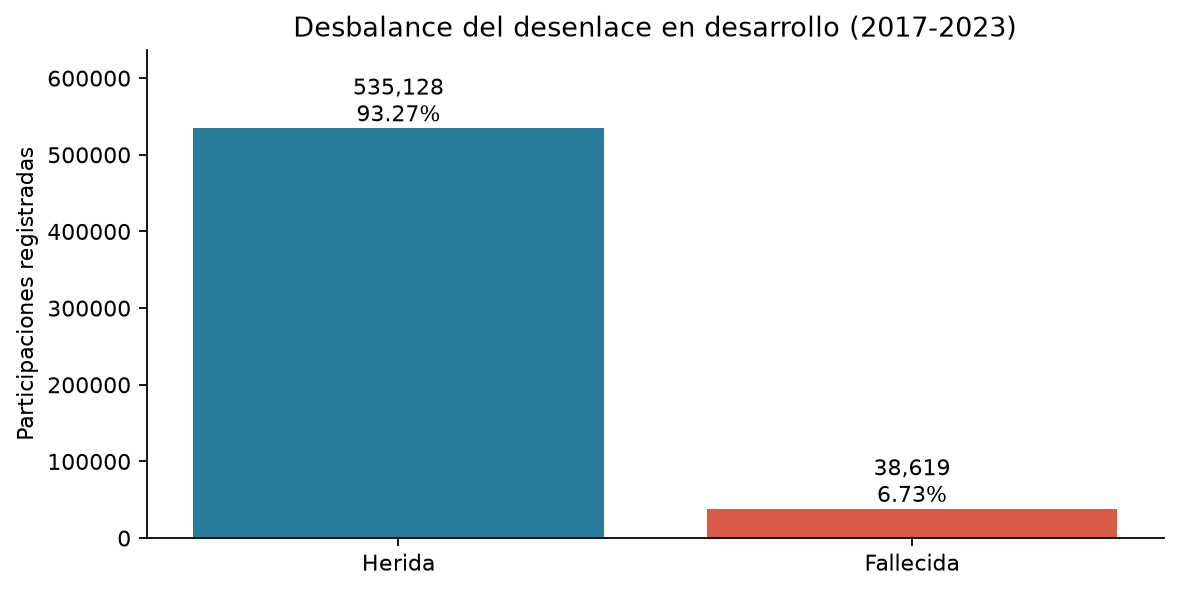

In [5]:
display(Image(filename=str(OUT/'figures/f1_01_clases.png')))

En desarrollo hay 38,619 fallecidos entre 573,747 víctimas (6.73%). La clase mayoritaria domina el total de aciertos, por lo que evaluar solo exactitud ocultaría los errores de fallecidos.

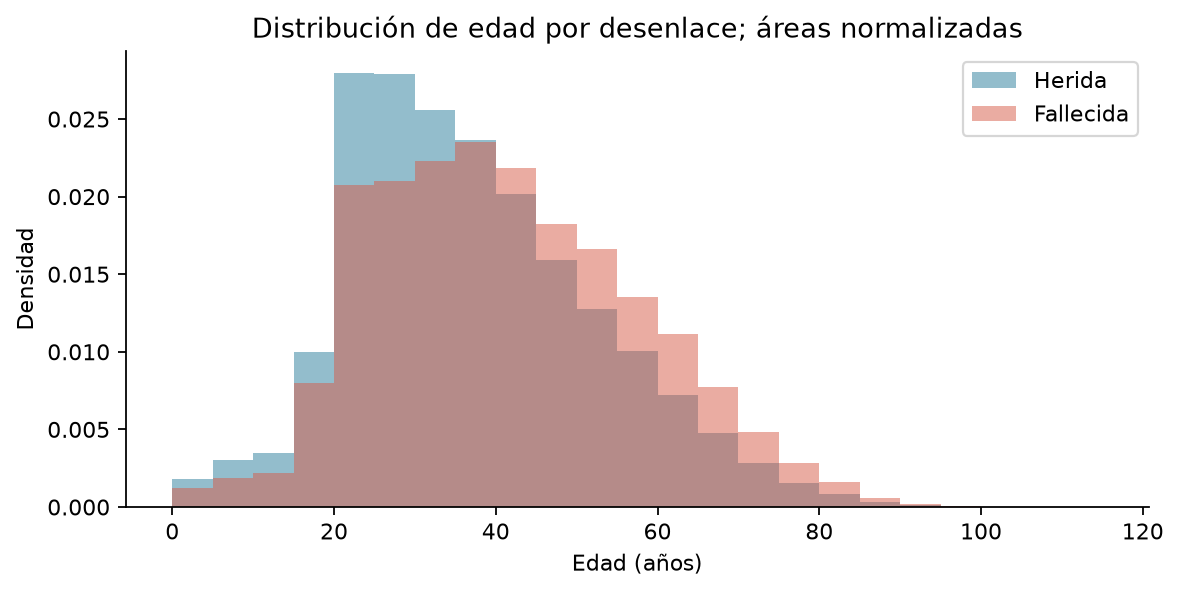

In [6]:
display(Image(filename=str(OUT/'figures/f1_02_histograma_edad.png')))

La mediana de edad registrada es 35 años en heridos y 39 en fallecidos. Se comparan densidades para que la mayor cantidad de heridos no oculte la distribución de fallecidos; edad faltante se conserva en los modelos mediante imputación.

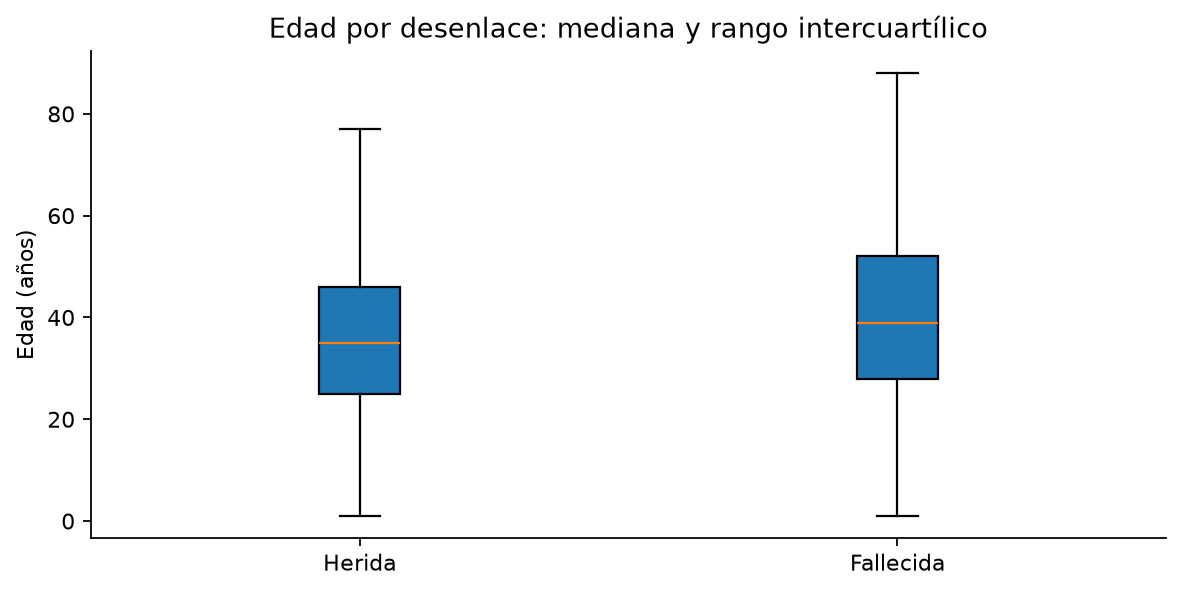

In [7]:
display(Image(filename=str(OUT/'figures/f1_03_cajas_edad.png')))

Las cajas muestran dispersión y superposición de edades. Una diferencia de centros entre grupos no permite clasificar perfectamente individuos; los bigotes no se usan para borrar edades plausibles.

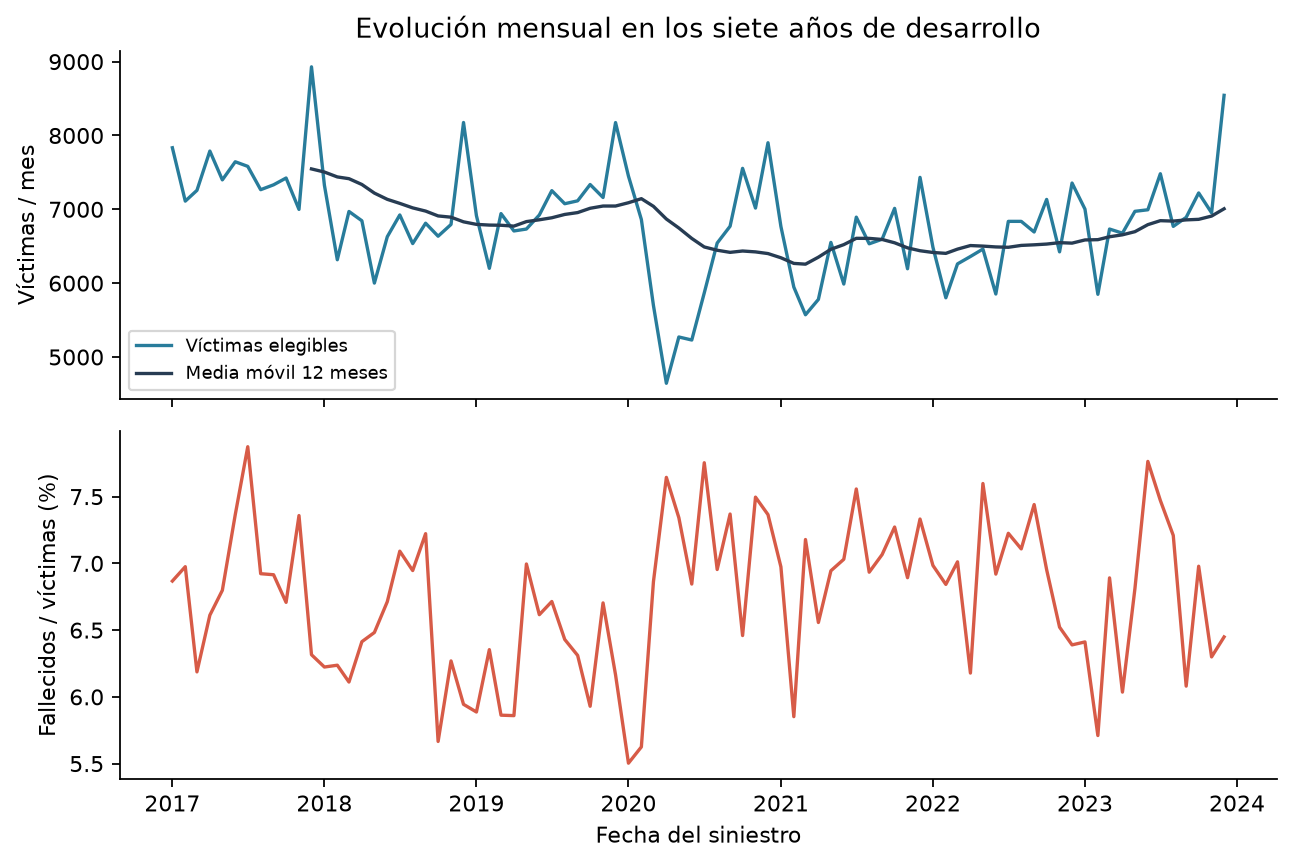

In [8]:
display(Image(filename=str(OUT/'figures/f1_04_serie_temporal.png')))

El volumen y la proporción de fallecimientos no permanecen idénticos todos los años. La serie corresponde a víctimas heridas o fallecidas registradas, sin medir exposición al tránsito; cambios de movilidad y registro pueden afectar las diferencias. Se respeta el orden temporal al validar.

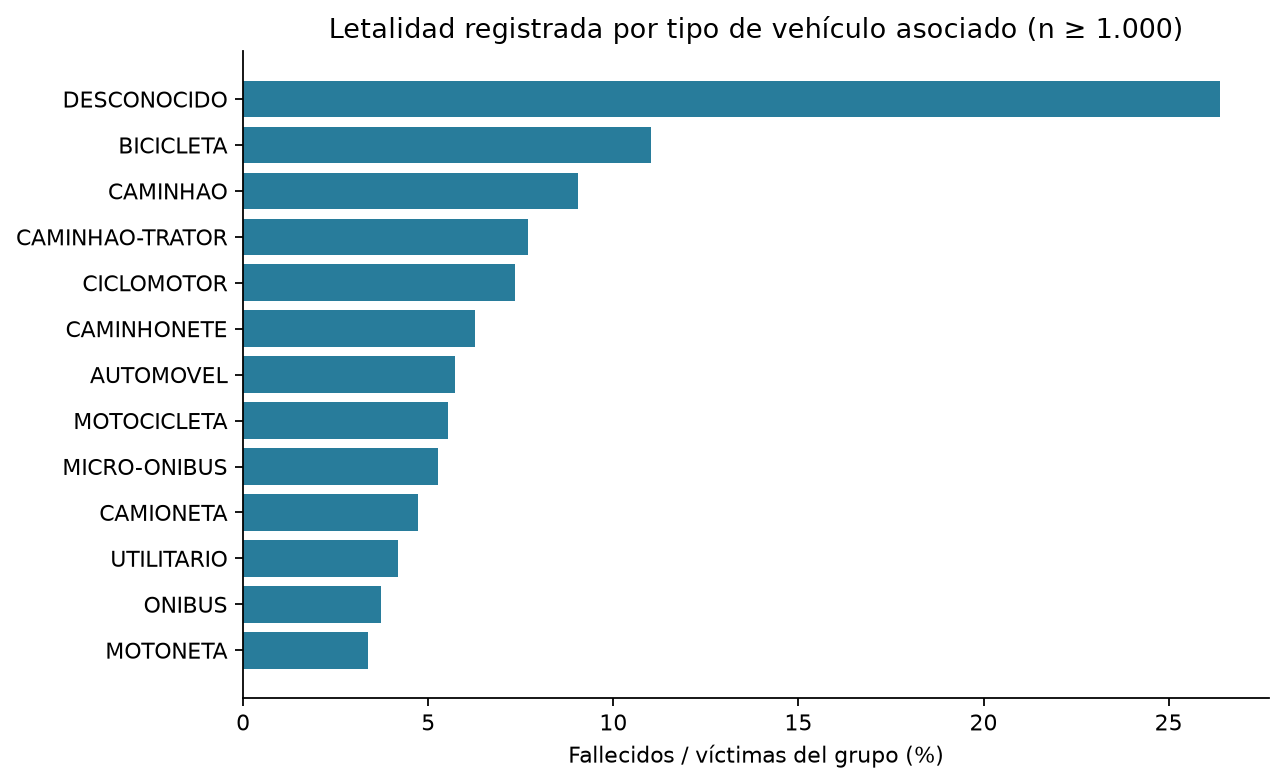

In [9]:
display(Image(filename=str(OUT/'figures/f1_05_vehiculos.png')))

Los tipos de vehículo muestran proporciones diferentes, calculadas con las víctimas de cada grupo como denominador. No representan riesgo por viaje ni una comparación causal; peatones y vehículo desconocido requieren interpretar el rol de participación.

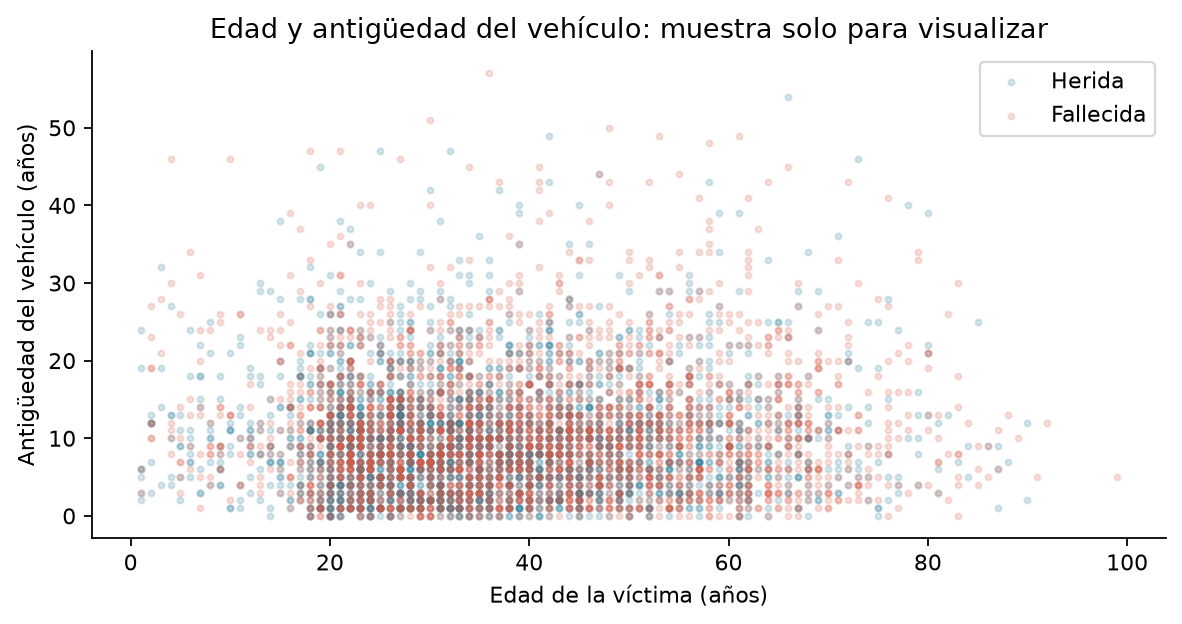

In [10]:
display(Image(filename=str(OUT/'figures/f1_06_dispersion.png')))

Se muestran 3.000 casos por clase únicamente para que ambas sean visibles. Este balance visual no modifica el entrenamiento ni la prueba. La superposición indica que dos características aisladas no separan completamente los desenlaces.

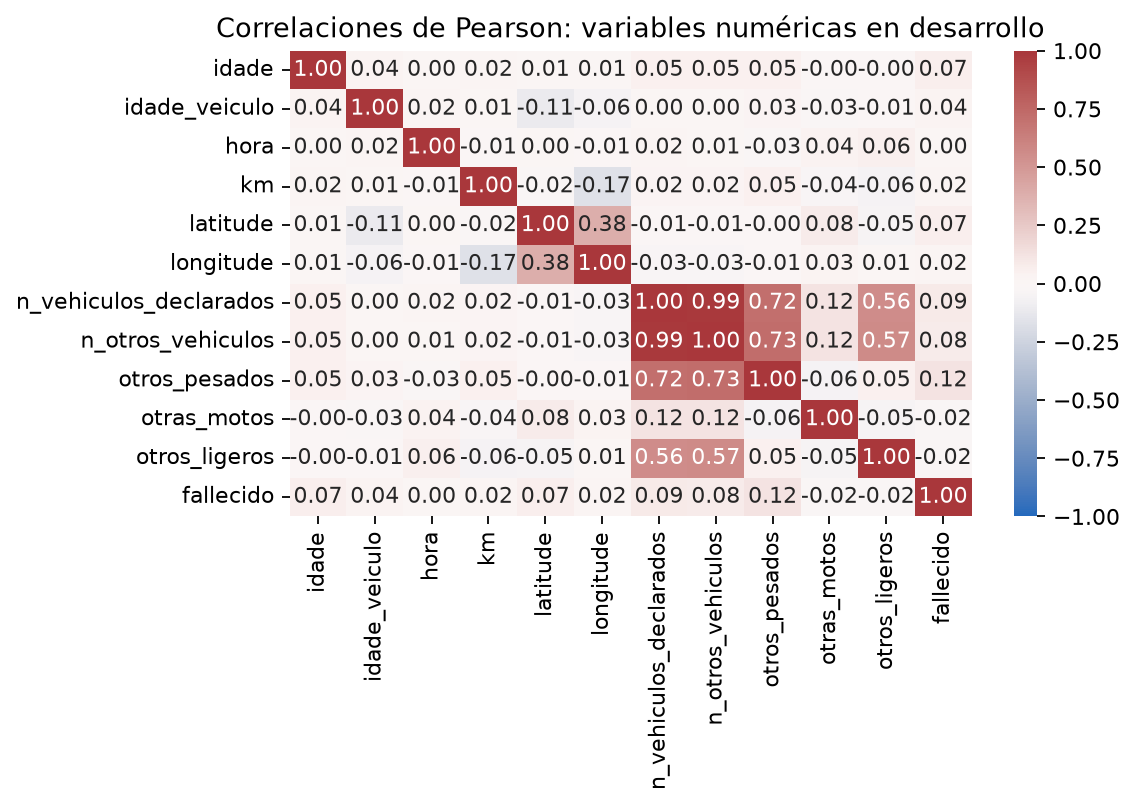

In [11]:
display(Image(filename=str(OUT/'figures/f1_07_correlaciones.png')))

La correlación lineal resume solo una parte de la relación. Latitud y longitud describen localización, y la variable binaria de desenlace permite una lectura descriptiva, sin demostrar causalidad ni sustituir la evaluación predictiva.

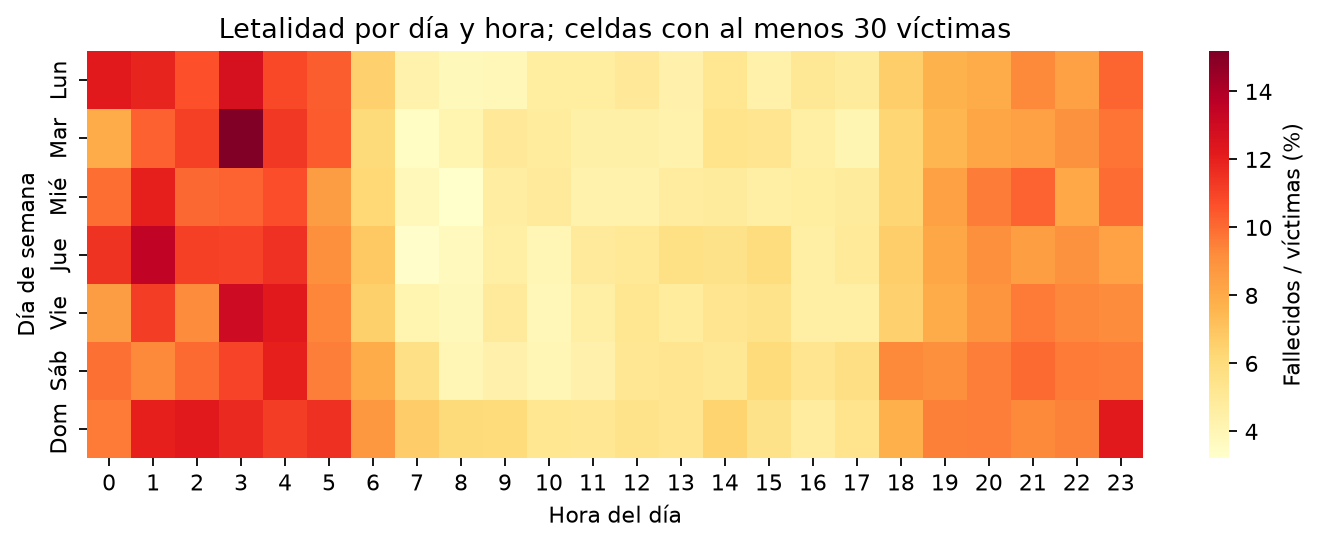

In [12]:
display(Image(filename=str(OUT/'figures/f1_08_dia_hora.png')))

El patrón horario justifica estudiar nocturnidad, con diferencias de exposición y tipo de siniestro como posibles confusores. Las celdas contienen víctimas, no conteos independientes de accidentes; un mapa más intenso no mide riesgo por kilómetro recorrido.

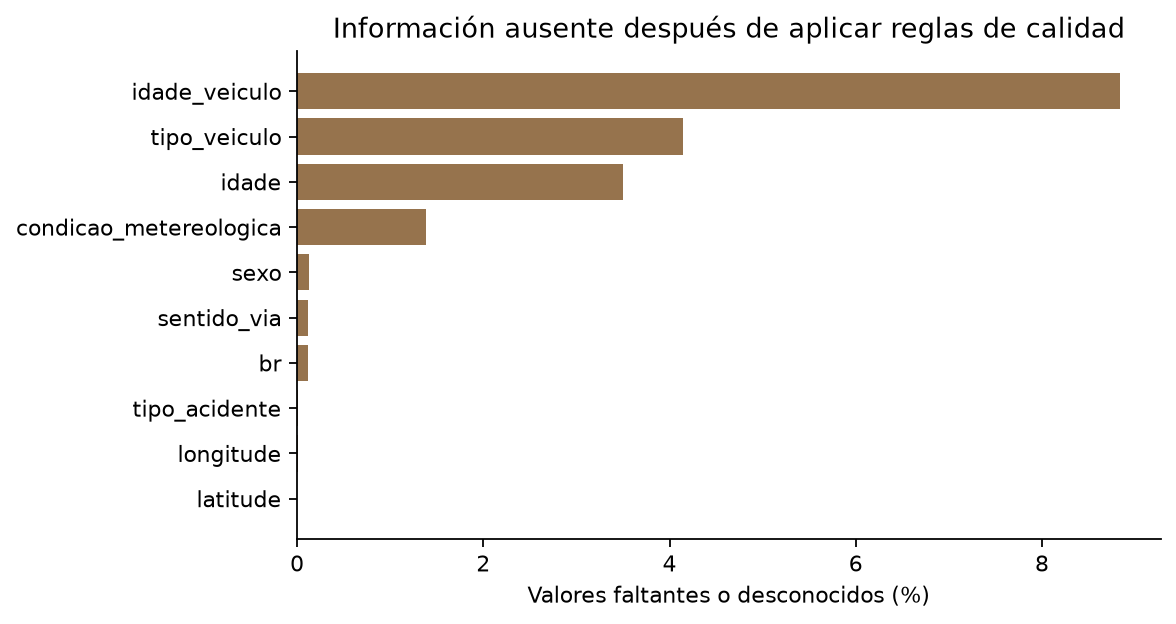

In [13]:
display(Image(filename=str(OUT/'figures/f1_09_faltantes.png')))

Las ausencias pueden relacionarse con el tipo de víctima y la calidad del registro; no se supone que falten completamente al azar. Se conservan filas y categorías desconocidas, con imputación numérica aprendida exclusivamente dentro de cada entrenamiento.

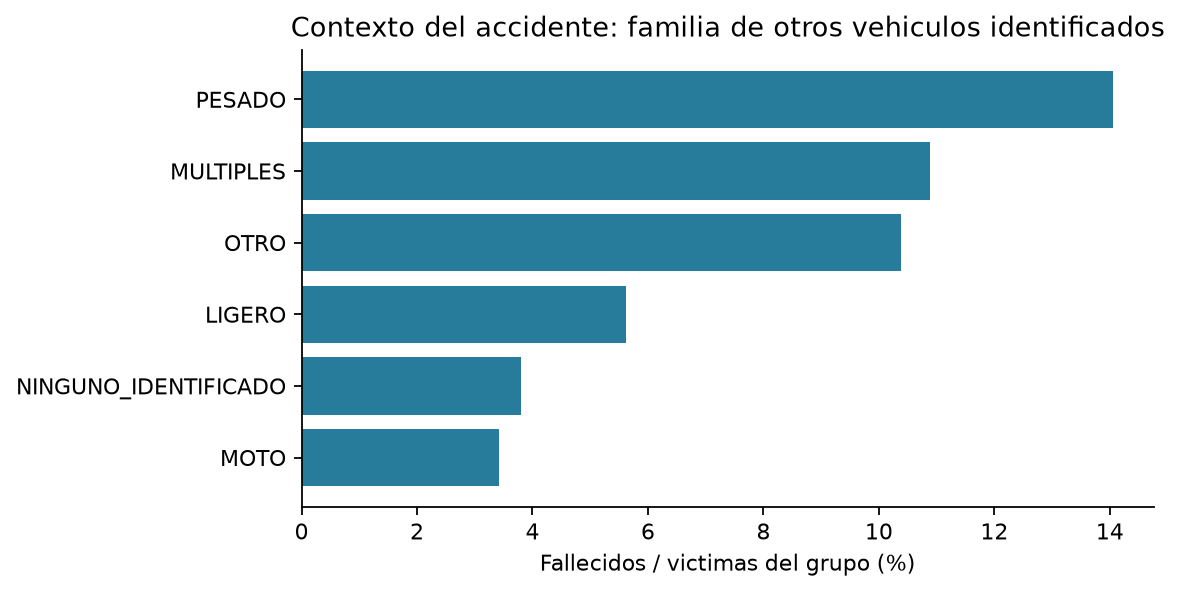

In [14]:
display(Image(filename=str(OUT/'figures/f1_10_contexto.png')))

El contexto de otros vehiculos permite caracterizar el mismo siniestro con claves reales. Las proporciones estan condicionadas a victimas lesionadas registradas; no son riesgo por viaje ni prueba causal. La categoria multiples no identifica parejas de colision.

## Conclusión y puente

Desbalance marcado, superposición de edades, diferencias por tipo/entorno y cambios temporales orientan H1 sexo, H2 edad, H3 usuario de moto y H4 nocturnidad ajustada. Se dispone de más información real por víctima y accidente. El contexto vehicular es una revisión iterativa de preparación para la fase predictiva; su utilidad no implica un efecto causal.